# Medellin Edge-Slope Filtration (10 Steps)

This notebook computes persistent homology for **Medellin** using a filtration driven by **edge slope** instead of node elevation. Each edge slope is computed as `abs(elevation_u - elevation_v) / length_m` (always non-negative).

In [8]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import osmnx as ox

%matplotlib inline
warnings.filterwarnings("ignore", category=UserWarning)

In [9]:
graph_path = Path("medellin_drive_with_elevation.graphml")
if not graph_path.exists():
    raise FileNotFoundError(f"Graph file not found: {graph_path.resolve()}")

G = ox.load_graphml(graph_path)
print(f"Loaded graph: {graph_path}")
print(f"Nodes: {G.number_of_nodes():,} | Edges: {G.number_of_edges():,}")

Loaded graph: medellin_drive_with_elevation.graphml
Nodes: 15,207 | Edges: 36,725


In [10]:
def _to_float(value):
    if value is None:
        return np.nan
    try:
        return float(value)
    except (TypeError, ValueError):
        return np.nan

# Node elevation lookup
node_elev = {
    n: _to_float(data.get("elevation_m", data.get("elevation")))
    for n, data in G.nodes(data=True)
}

valid_nodes = [n for n, e in node_elev.items() if np.isfinite(e)]
if not valid_nodes:
    raise ValueError("No valid elevation attribute found on graph nodes.")

for n in valid_nodes:
    G.nodes[n]["elevation_m"] = float(node_elev[n])

valid_elev = np.array([node_elev[n] for n in valid_nodes], dtype=float)
missing = G.number_of_nodes() - len(valid_nodes)

# Edge slope lookup: abs(delta elevation)/length (m/m), always non-negative
edge_slope = {}
for u, v, k, data in G.edges(keys=True, data=True):
    eu = node_elev.get(u, np.nan)
    ev = node_elev.get(v, np.nan)
    length_m = _to_float(data.get("length"))

    if not (np.isfinite(eu) and np.isfinite(ev)):
        continue
    if not (np.isfinite(length_m) and length_m > 0):
        continue

    slope = abs(ev - eu) / length_m
    if np.isfinite(slope):
        edge_slope[(u, v, k)] = float(slope)

if not edge_slope:
    raise ValueError("No valid edge slope could be computed. Check elevation and edge length attributes.")

slope_values = np.array(list(edge_slope.values()), dtype=float)

print(f"Nodes with valid elevation: {len(valid_nodes):,}")
print(f"Nodes missing elevation: {missing:,}")
print(f"Elevation range (m): {valid_elev.min():.2f} to {valid_elev.max():.2f}")
print(f"Edges with valid slope: {len(edge_slope):,}")
print(f"Slope range (m/m): {slope_values.min():.6f} to {slope_values.max():.6f}")

Nodes with valid elevation: 15,207
Nodes missing elevation: 0
Elevation range (m): 1433.00 to 2104.00
Edges with valid slope: 36,725
Slope range (m/m): 0.000000 to 0.763820


In [11]:
n_steps = 10

def build_slope_filtration(G, edge_slope, n_steps=10):
    """
    Build filtration by edge-slope percentiles.
    Step k includes edges with slope <= percentile(k*10),
    with incident nodes only.
    """
    if n_steps <= 0:
        raise ValueError("n_steps must be > 0")
    if not edge_slope:
        raise ValueError("edge_slope is empty")

    slope_values = np.array(list(edge_slope.values()), dtype=float)
    percentiles = np.linspace(100 / n_steps, 100, n_steps)
    thresholds = np.percentile(slope_values, percentiles)

    filtration = []
    for step, (pct, thr) in enumerate(zip(percentiles, thresholds), start=1):
        edges_step = [edge for edge, slope in edge_slope.items() if slope <= thr]
        H = G.edge_subgraph(edges_step).copy()

        U = nx.Graph(H.to_undirected())
        U.remove_edges_from(nx.selfloop_edges(U))

        n_nodes = U.number_of_nodes()
        n_edges = U.number_of_edges()
        beta0 = nx.number_connected_components(U) if n_nodes > 0 else 0
        beta1 = n_edges - n_nodes + beta0 if n_nodes > 0 else 0

        filtration.append({
            "step": step,
            "percentile": float(pct),
            "threshold_slope": float(thr),
            "graph": H,
            "edges": set(edges_step),
            "n_nodes": int(H.number_of_nodes()),
            "n_edges": int(H.number_of_edges()),
            "beta0": int(beta0),
            "beta1": int(beta1),
        })

    return filtration

filtration = build_slope_filtration(G, edge_slope=edge_slope, n_steps=n_steps)

summary_df = pd.DataFrame([
    {
        "step": f["step"],
        "percentile": f["percentile"],
        "threshold_slope": f["threshold_slope"],
        "nodes": f["n_nodes"],
        "edges": f["n_edges"],
        "beta0": f["beta0"],
        "beta1": f["beta1"],
    }
    for f in filtration
])

summary_df

,step,percentile,threshold_slope,nodes,edges,beta0,beta1
0,1,10.0,0.000000,4211,3785,1783,56
1,2,20.0,0.018940,7081,7346,2362,134
2,3,30.0,0.030961,9173,11018,2337,346
3,4,40.0,0.044557,10823,14690,2100,802
4,5,50.0,0.061566,12061,18363,1834,1582
5,6,60.0,0.081241,13057,22035,1448,2453
6,7,70.0,0.105339,13821,25707,1004,3460
7,8,80.0,0.139389,14397,29381,552,4566
8,9,90.0,0.191450,14819,33052,204,5847
9,10,100.0,0.763820,15207,36725,1,7228


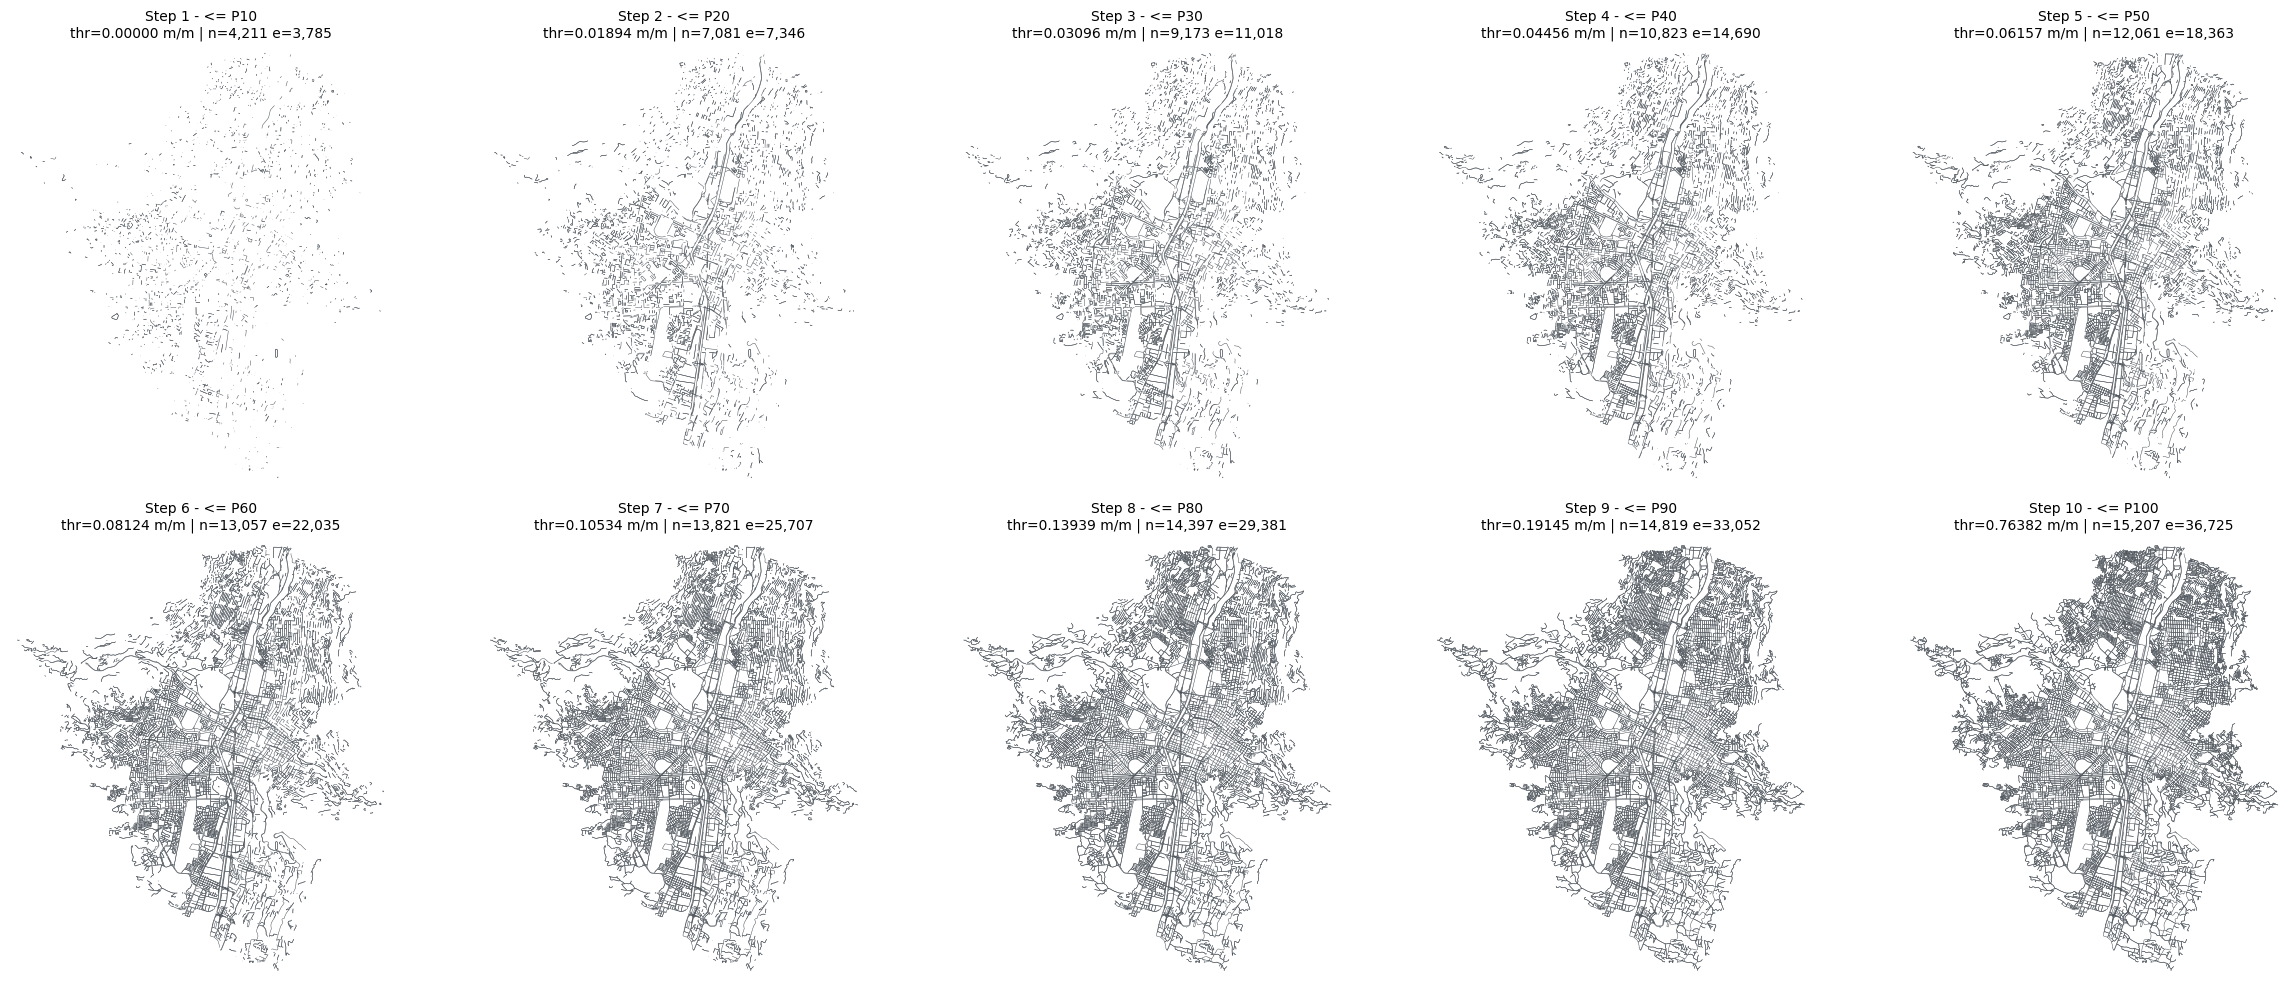

In [12]:
fig, axes = plt.subplots(2, 5, figsize=(24, 10))
axes = axes.ravel()

for ax, item in zip(axes, filtration):
    H = item["graph"]
    title = (
        f"Step {item['step']} - <= P{int(item['percentile'])}\n"
        f"thr={item['threshold_slope']:.5f} m/m | n={item['n_nodes']:,} e={item['n_edges']:,}"
    )

    if H.number_of_nodes() == 0:
        ax.set_title(title)
        ax.axis("off")
        continue

    ox.plot_graph(
        H,
        ax=ax,
        show=False,
        close=False,
        node_size=0,
        edge_linewidth=0.35,
        node_color="#0b7285",
        edge_color="#495057",
        bgcolor="white",
    )
    ax.set_title(title, fontsize=10)
    ax.set_axis_off()

plt.tight_layout()
plt.show()

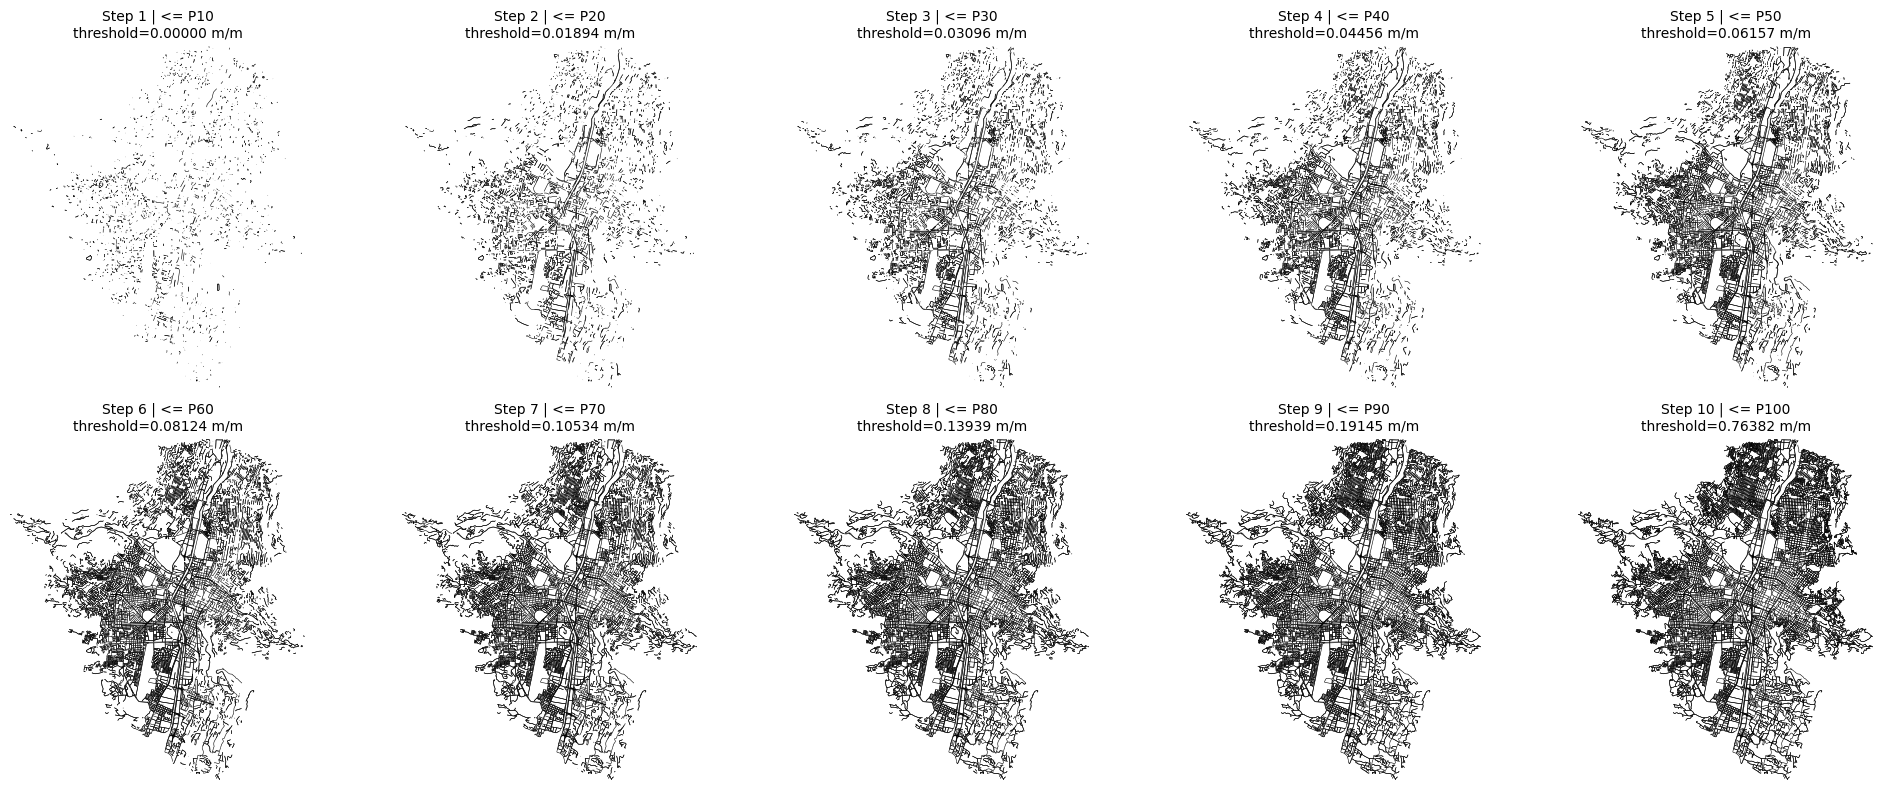


Final graph summary
Nodes: 15207
Edges: 22434

Simplex tree summary
Dimension: 1
Num vertices: 15207
Num simplices: 37641

Finite H1 intervals:
[]

Graph-theoretic diagnostics
Connected components: 1
Cycle rank: 7228

Betti numbers:
[1, 7228]


<Figure size 700x600 with 0 Axes>

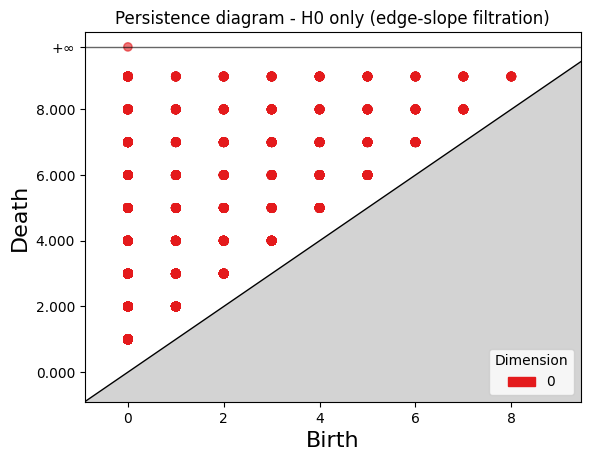

<Figure size 1000x400 with 0 Axes>

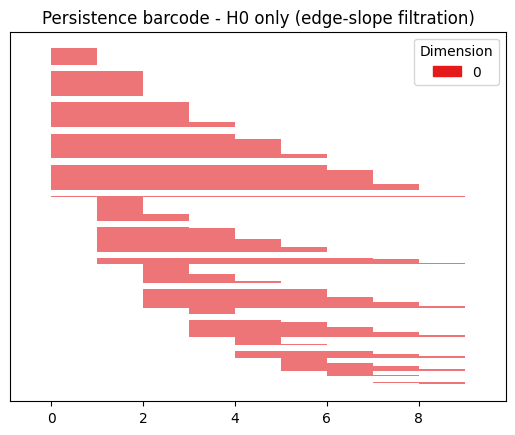

<Figure size 700x600 with 0 Axes>

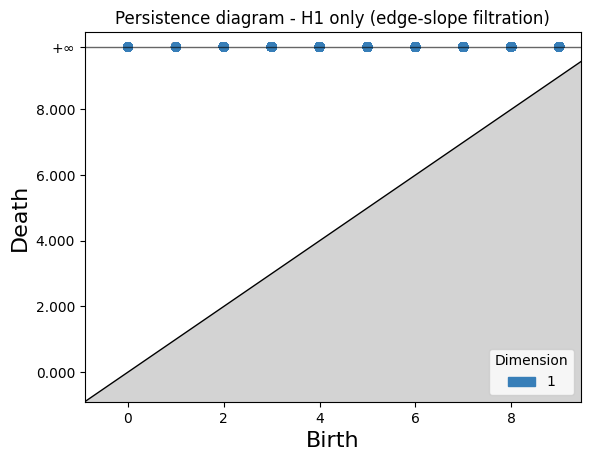

<Figure size 1000x400 with 0 Axes>

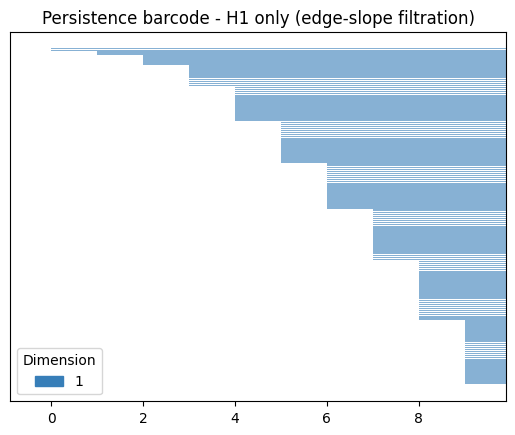


Step-by-step filtration summary

Step 1 -> <= P10 (threshold=0.00000 m/m)
Nodes: 4211
Edges: 2484
Connected components: 1783
Cycle rank: 56

Step 2 -> <= P20 (threshold=0.01894 m/m)
Nodes: 7081
Edges: 4853
Connected components: 2362
Cycle rank: 134

Step 3 -> <= P30 (threshold=0.03096 m/m)
Nodes: 9173
Edges: 7182
Connected components: 2337
Cycle rank: 346

Step 4 -> <= P40 (threshold=0.04456 m/m)
Nodes: 10823
Edges: 9525
Connected components: 2100
Cycle rank: 802

Step 5 -> <= P50 (threshold=0.06157 m/m)
Nodes: 12061
Edges: 11809
Connected components: 1834
Cycle rank: 1582

Step 6 -> <= P60 (threshold=0.08124 m/m)
Nodes: 13057
Edges: 14062
Connected components: 1448
Cycle rank: 2453

Step 7 -> <= P70 (threshold=0.10534 m/m)
Nodes: 13821
Edges: 16277
Connected components: 1004
Cycle rank: 3460

Step 8 -> <= P80 (threshold=0.13939 m/m)
Nodes: 14397
Edges: 18411
Connected components: 552
Cycle rank: 4566

Step 9 -> <= P90 (threshold=0.19145 m/m)
Nodes: 14819
Edges: 20462
Connected compon

In [13]:
# If needed once:
# !pip install gudhi

import gudhi

ox.settings.use_cache = True
ox.settings.log_console = True

n_steps = 10
percentiles = np.arange(10, 101, 10)

def to_float(x):
    try:
        val = float(x)
        return val if np.isfinite(val) else np.nan
    except (TypeError, ValueError):
        return np.nan

# Node elevations
node_elev = {}
for n, data in G.nodes(data=True):
    e = data.get("elevation_m", data.get("elevation"))
    e = to_float(e)
    if np.isfinite(e):
        node_elev[n] = e

if len(node_elev) == 0:
    raise ValueError("No valid elevation attribute found (expected 'elevation_m' or 'elevation').")

# Edge slopes (always positive)
edge_slope = {}
for u, v, k, data in G.edges(keys=True, data=True):
    eu = node_elev.get(u, np.nan)
    ev = node_elev.get(v, np.nan)
    length_m = to_float(data.get("length"))

    if not (np.isfinite(eu) and np.isfinite(ev)):
        continue
    if not (np.isfinite(length_m) and length_m > 0):
        continue

    slope = abs(ev - eu) / length_m
    if np.isfinite(slope):
        edge_slope[(u, v, k)] = float(slope)

if len(edge_slope) == 0:
    raise ValueError("No valid edge slope computed.")

slope_values = np.array(list(edge_slope.values()), dtype=float)
thresholds = np.percentile(slope_values, percentiles)

# Edge filtration time: first step where edge appears (0..9)
edge_filtration = {}
for edge_key, s in edge_slope.items():
    t = int(np.searchsorted(thresholds, s, side="left"))
    t = min(t, n_steps - 1)
    edge_filtration[edge_key] = t

# Node filtration time: first incident edge appearance
node_filtration = {}
for (u, v, _k), t in edge_filtration.items():
    if u in node_filtration:
        node_filtration[u] = min(node_filtration[u], t)
    else:
        node_filtration[u] = t

    if v in node_filtration:
        node_filtration[v] = min(node_filtration[v], t)
    else:
        node_filtration[v] = t

# Prepare edge GeoDataFrame for snapshots
edges = ox.graph_to_gdfs(G, nodes=False).copy()
u_idx = edges.index.get_level_values(0)
v_idx = edges.index.get_level_values(1)
k_idx = edges.index.get_level_values(2)

mask = [(u, v, k) in edge_filtration for u, v, k in zip(u_idx, v_idx, k_idx)]
edges = edges[mask].copy()

u_idx = edges.index.get_level_values(0)
v_idx = edges.index.get_level_values(1)
k_idx = edges.index.get_level_values(2)

edges["slope"] = [edge_slope[(u, v, k)] for u, v, k in zip(u_idx, v_idx, k_idx)]
edges["filtration"] = [edge_filtration[(u, v, k)] for u, v, k in zip(u_idx, v_idx, k_idx)]

xmin, ymin, xmax, ymax = edges.total_bounds

# Plot filtration snapshots
cols = 5
rows = int(np.ceil(n_steps / cols))

fig, axes = plt.subplots(rows, cols, figsize=(20, 4 * rows))
axes = np.array(axes).flatten()

for t in range(n_steps):
    ax = axes[t]
    subset = edges[edges["filtration"] <= t]

    if not subset.empty:
        subset.plot(ax=ax, linewidth=0.4, color="black")

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_title(
        f"Step {t+1} | <= P{(t+1)*10}\nthreshold={thresholds[t]:.5f} m/m",
        fontsize=10
    )
    ax.set_axis_off()

for j in range(n_steps, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

# Build simple undirected graph for PH (1-skeleton)
H = nx.Graph()

for n, t in node_filtration.items():
    H.add_node(n, filtration=t)

for (u, v, _k), t in edge_filtration.items():
    if u == v:
        continue
    if (u not in node_filtration) or (v not in node_filtration):
        continue

    if H.has_edge(u, v):
        H[u][v]["filtration"] = min(H[u][v]["filtration"], t)
    else:
        H.add_edge(u, v, filtration=t)

print("\nFinal graph summary")
print("Nodes:", H.number_of_nodes())
print("Edges:", H.number_of_edges())

# Build Gudhi simplex tree
st = gudhi.SimplexTree()

node_to_int = {node: i for i, node in enumerate(H.nodes())}

for node, data in H.nodes(data=True):
    st.insert([node_to_int[node]], filtration=float(data["filtration"]))

for u, v, data in H.edges(data=True):
    st.insert([node_to_int[u], node_to_int[v]], filtration=float(data["filtration"]))

st.make_filtration_non_decreasing()

print("\nSimplex tree summary")
print("Dimension:", st.dimension())
print("Num vertices:", st.num_vertices())
print("Num simplices:", st.num_simplices())

# Compute persistence
diag = st.persistence(
    homology_coeff_field=2,
    persistence_dim_max=True
)

h0 = st.persistence_intervals_in_dimension(0)
h1 = st.persistence_intervals_in_dimension(1)

h1_finite = h1[np.isfinite(h1).all(axis=1)] if len(h1) > 0 else np.empty((0, 2))
print("\nFinite H1 intervals:")
print(h1_finite)

if len(h1_finite) > 0:
    h1_lengths = h1_finite[:, 1] - h1_finite[:, 0]
    print("\nFinite H1 bar lengths:")
    print(h1_lengths)

# Graph-theoretic check
c = nx.number_connected_components(H)
m = H.number_of_edges()
n_nodes = H.number_of_nodes()
cycle_rank = m - n_nodes + c

print("\nGraph-theoretic diagnostics")
print("Connected components:", c)
print("Cycle rank:", cycle_rank)

# Betti numbers
bettis = st.betti_numbers()
print("\nBetti numbers:")
print(bettis)

# Plot H0 only
if len(h0) > 0:
    h0_diag = [(0, (birth, death)) for birth, death in h0]

    plt.figure(figsize=(7, 6))
    gudhi.plot_persistence_diagram(h0_diag)
    plt.title("Persistence diagram - H0 only (edge-slope filtration)")
    plt.show()

    plt.figure(figsize=(10, 4))
    gudhi.plot_persistence_barcode(h0_diag)
    plt.title("Persistence barcode - H0 only (edge-slope filtration)")
    plt.show()
else:
    print("\nNo H0 intervals found.")

# Plot H1 only
if len(h1) > 0:
    h1_diag = [(1, (birth, death)) for birth, death in h1]

    plt.figure(figsize=(7, 6))
    gudhi.plot_persistence_diagram(h1_diag)
    plt.title("Persistence diagram - H1 only (edge-slope filtration)")
    plt.show()

    plt.figure(figsize=(10, 4))
    gudhi.plot_persistence_barcode(h1_diag)
    plt.title("Persistence barcode - H1 only (edge-slope filtration)")
    plt.show()
else:
    print("\nNo H1 intervals found.")

# Step-by-step filtration check
print("\nStep-by-step filtration summary")
for t in range(n_steps):
    nodes_t = [n for n, d in H.nodes(data=True) if d["filtration"] <= t]
    edges_t = [(u, v) for u, v, d in H.edges(data=True) if d["filtration"] <= t]

    G_t = nx.Graph()
    G_t.add_nodes_from(nodes_t)
    G_t.add_edges_from(edges_t)

    n_t = G_t.number_of_nodes()
    m_t = G_t.number_of_edges()
    c_t = nx.number_connected_components(G_t) if n_t > 0 else 0
    cycle_rank_t = m_t - n_t + c_t if n_t > 0 else 0

    print(f"\nStep {t+1} -> <= P{(t+1)*10} (threshold={thresholds[t]:.5f} m/m)")
    print("Nodes:", n_t)
    print("Edges:", m_t)
    print("Connected components:", c_t)
    print("Cycle rank:", cycle_rank_t)

In [14]:
rows = []

for f in filtration:
    H = f["graph"]

    U = nx.Graph(H.to_undirected())
    U.remove_edges_from(nx.selfloop_edges(U))

    n = U.number_of_nodes()
    m = U.number_of_edges()
    c = nx.number_connected_components(U) if n > 0 else 0

    beta1 = (m - n + c) if n > 0 else 0
    cycle_edge_ratio = (beta1 / m) if m > 0 else np.nan

    rows.append({
        "step": f["step"],
        "percentile": f["percentile"],
        "threshold_slope": f["threshold_slope"],
        "nodes": n,
        "edges": m,
        "beta1_cycles": beta1,
        "cycle_edge_ratio": cycle_edge_ratio,
    })

cycle_edge_df = pd.DataFrame(rows)
cycle_edge_df

,step,percentile,threshold_slope,nodes,edges,beta1_cycles,cycle_edge_ratio
0,1,10.0,0.000000,4211,2484,56,0.022544
1,2,20.0,0.018940,7081,4853,134,0.027612
2,3,30.0,0.030961,9173,7182,346,0.048176
3,4,40.0,0.044557,10823,9525,802,0.084199
4,5,50.0,0.061566,12061,11809,1582,0.133966
5,6,60.0,0.081241,13057,14062,2453,0.174442
6,7,70.0,0.105339,13821,16277,3460,0.212570
7,8,80.0,0.139389,14397,18411,4566,0.248004
8,9,90.0,0.191450,14819,20462,5847,0.285749
9,10,100.0,0.763820,15207,22434,7228,0.322190


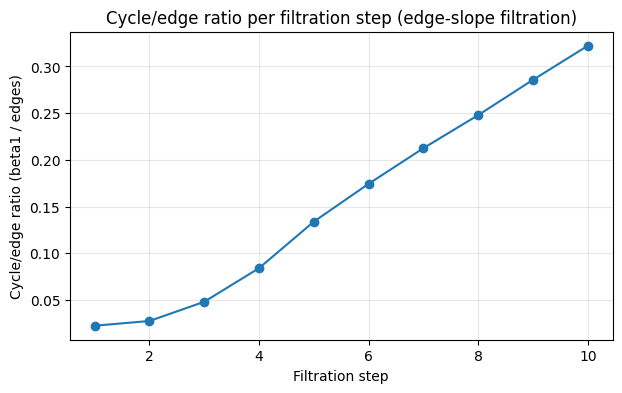

In [15]:
plt.figure(figsize=(7, 4))
plt.plot(cycle_edge_df["step"], cycle_edge_df["cycle_edge_ratio"], marker="o")
plt.xlabel("Filtration step")
plt.ylabel("Cycle/edge ratio (beta1 / edges)")
plt.title("Cycle/edge ratio per filtration step (edge-slope filtration)")
plt.grid(alpha=0.3)
plt.show()

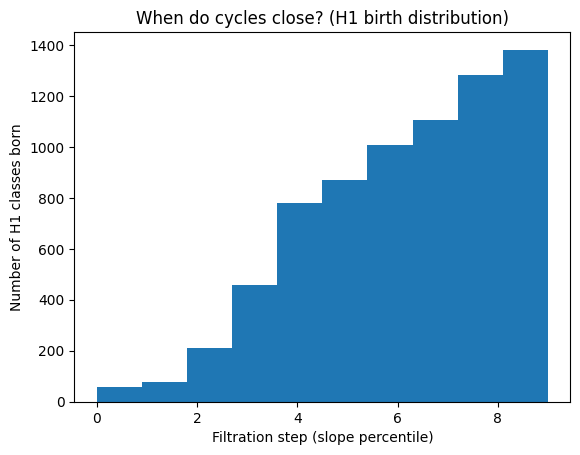

In [16]:
if len(h1) > 0:
    h1_births = h1[:, 0]
    plt.hist(h1_births, bins=n_steps)
    plt.xlabel("Filtration step (slope percentile)")
    plt.ylabel("Number of H1 classes born")
    plt.title("When do cycles close? (H1 birth distribution)")
    plt.show()
else:
    print("No H1 intervals available for birth histogram.")

In [17]:
node_additions = [
    filtration[t]["n_nodes"] - (filtration[t - 1]["n_nodes"] if t > 0 else 0)
    for t in range(n_steps)
]

if len(h1) > 0:
    h1_births_per_step = [sum(1 for b, _ in h1 if int(b) == t) for t in range(n_steps)]
else:
    h1_births_per_step = [0] * n_steps

cycle_per_node_added = [
    h / n if n > 0 else 0
    for h, n in zip(h1_births_per_step, node_additions)
]

In [18]:
cycle_per_node_added

[0.01329850391830919,
 0.027177700348432057,
 0.10133843212237094,
 0.27636363636363637,
 0.630048465266559,
 0.8744979919678715,
 1.318062827225131,
 1.9201388888888888,
 3.0355450236966823,
 3.5592783505154637]

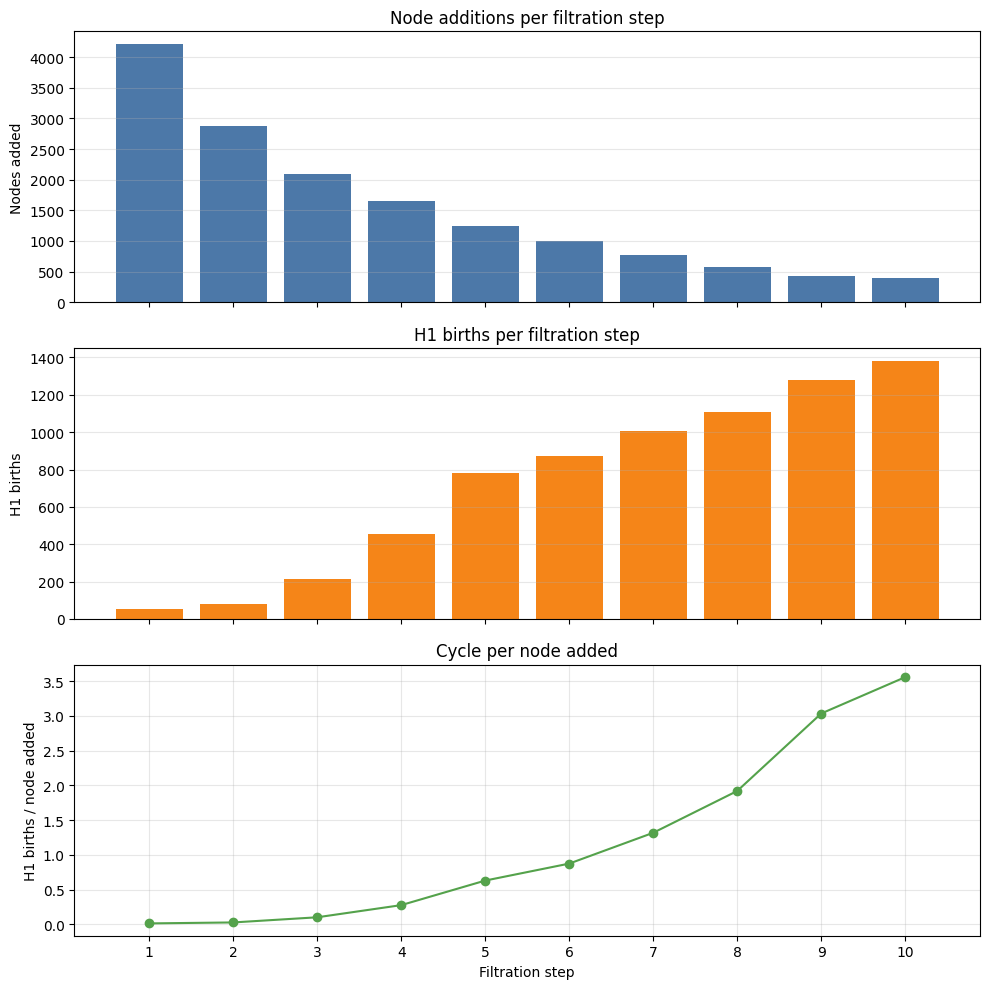

In [19]:
steps = np.arange(1, n_steps + 1)

fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True)

axes[0].bar(steps, node_additions, color="#4c78a8")
axes[0].set_ylabel("Nodes added")
axes[0].set_title("Node additions per filtration step")
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(steps, h1_births_per_step, color="#f58518")
axes[1].set_ylabel("H1 births")
axes[1].set_title("H1 births per filtration step")
axes[1].grid(axis="y", alpha=0.3)

axes[2].plot(steps, cycle_per_node_added, marker="o", color="#54a24b")
axes[2].set_ylabel("H1 births / node added")
axes[2].set_xlabel("Filtration step")
axes[2].set_title("Cycle per node added")
axes[2].grid(alpha=0.3)

plt.xticks(steps)
plt.tight_layout()
plt.show()